In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sqlalchemy import create_engine
import seaborn as sns

In [2]:
server = 'localhost\\SQLEXPRESS'

database = 'Sales_DataWareHouse'

Connection_url = f"mssql+pyodbc://@{server}/{database}?driver=ODBC+Driver+17+for+SQL+server&Trusted_Connection=Yes"
try:
    engine = create_engine(Connection_url)
    print("Connection successful! Engine is ready.")
except Exception as e:
    print(f"Error in connection {e}")

Connection successful! Engine is ready.


In [3]:
db_tables = ['gold.dim_customer','gold.dim_product','gold.dim_orders','gold.fact_sales']
df = {}

for i in db_tables:
    query = f'SELECT * FROM {i}'
    data = pd.read_sql(query,con=engine)
    df[i] = data

# **The Scenario:** 
## **Uncovering Margin Leakage in High-Value Segments**
### The marketing team is preparing to launch a new VIP loyalty program. They want to target the most valuable customers, but the finance team is concerned that high revenue doesn't always mean high profit. They suspect that some top spenders are heavily relying on coupon codes or predominantly buying products that incur high shipping costs.

# **Your Analytical Tasks:**
## **1. Segment the VIPs:**
### Using the sales and customer datasets, identify the top 5% of customers based on their overall lifetime value (using the calculated total_amount of successful, delivered orders).

## **2. Analyze Margin Leakage:** 
### For this top 5% cohort, integrate the product data to determine which product categories they purchase most frequently. Calculate the ratio of coupon_discount to the base order_value for these categories. Are there specific categories where your VIPs are disproportionately using coupons, effectively shrinking the margins?

## **3. Evaluate the Delivery Experience:**
### Finally, incorporate the order data to analyze the fulfillment experience of these VIPs. Calculate the delivery lead time (the difference between order_date and delivery_date). Does a longer delivery time correlate with a noticeably lower rating for these top-tier customers?

In [4]:
data  = df['gold.fact_sales'].merge(df['gold.dim_orders'], on = 'order_id', how = 'left')

In [5]:
data = data.merge(df['gold.dim_customer'], on = 'customer_id', how = 'left')

In [6]:
data = data.merge(df['gold.dim_product'], on = 'product_id', how = 'left')

In [7]:
data.shape

(250000, 45)

In [8]:
data['customer_name'] = (data['customer_first_name'] + ' ' + data['customer_last_name'])

In [9]:
data = data[['order_id', 'customer_id', 'product_id','customer_name', 'gender', 'age','age_group', 'dob', 'city_y', 'state_y', 'pinecode','registration_date', 'tier','total_orders', 'total_spent','product_name','category','brand','price','discount_percent','discount_amount','selling_amount','stock_quantity','avg_rating', 'total_reviews', 'payment_mode', 'order_status', 'rating', 'city_x','state_x','order_date', 'order_time', 'delivery_date','quantity', 'unit_price','order_value', 'shipping_cost', 'coupon_code', 'coupon_discount','total_amount']]

In [10]:
data = data.rename(columns={'city_y':'customer_city', 'state_y':'customer_state','city_x':'order_city','state_x':'order_state'})

In [11]:
data.columns

Index(['order_id', 'customer_id', 'product_id', 'customer_name', 'gender',
       'age', 'age_group', 'dob', 'customer_city', 'customer_state',
       'pinecode', 'registration_date', 'tier', 'total_orders', 'total_spent',
       'product_name', 'category', 'brand', 'price', 'discount_percent',
       'discount_amount', 'selling_amount', 'stock_quantity', 'avg_rating',
       'total_reviews', 'payment_mode', 'order_status', 'rating', 'order_city',
       'order_state', 'order_date', 'order_time', 'delivery_date', 'quantity',
       'unit_price', 'order_value', 'shipping_cost', 'coupon_code',
       'coupon_discount', 'total_amount'],
      dtype='str')

In [12]:
data['order_status'].unique()

<StringArray>
['Delivered', 'Processing', 'Returned', 'Cancelled', 'Shipped']
Length: 5, dtype: str

In [13]:
delivered_data = data[data['order_status'] == 'Delivered']

In [14]:
delivered_data.columns

Index(['order_id', 'customer_id', 'product_id', 'customer_name', 'gender',
       'age', 'age_group', 'dob', 'customer_city', 'customer_state',
       'pinecode', 'registration_date', 'tier', 'total_orders', 'total_spent',
       'product_name', 'category', 'brand', 'price', 'discount_percent',
       'discount_amount', 'selling_amount', 'stock_quantity', 'avg_rating',
       'total_reviews', 'payment_mode', 'order_status', 'rating', 'order_city',
       'order_state', 'order_date', 'order_time', 'delivery_date', 'quantity',
       'unit_price', 'order_value', 'shipping_cost', 'coupon_code',
       'coupon_discount', 'total_amount'],
      dtype='str')

In [15]:
delivered_data

,order_id,customer_id,product_id,customer_name,gender,age,age_group,dob,customer_city,customer_state,...,order_date,order_time,delivery_date,quantity,unit_price,order_value,shipping_cost,coupon_code,coupon_discount,total_amount
0,ORD0000000001,CUST00014303,PROD001017,Suresh Shah,male,43,36-45,1982-01-12,Chennai,Tamil Nadu,...,2026-06-07,08:20:00,2026-06-10,1,2622.46,2622.46,0.0,NaN,0.00,2622.46
1,ORD0000000002,CUST00034253,PROD000703,Amit Nair,male,22,18-25,2003-01-07,Durgapur,West Bengal,...,2025-02-04,20:05:00,2025-02-07,1,90258.00,90258.00,0.0,NaN,0.00,90258.00
3,ORD0000000004,CUST00026507,PROD000213,Kavya Gupta,female,29,26-35,1996-01-09,Rajkot,Gujarat,...,2025-01-27,14:33:00,2025-02-02,1,34081.56,34081.56,0.0,FLAT50,50.00,34031.56
4,ORD0000000005,CUST00009418,PROD001437,Suresh Tiwari,male,39,36-45,1986-01-11,Surat,Gujarat,...,2024-06-30,07:19:00,2024-07-02,2,69021.17,138042.34,0.0,NaN,0.00,138042.34
7,ORD0000000008,CUST00017326,PROD001392,Amina Khan,female,20,18-25,2005-01-06,Delhi NCR,Delhi,...,2024-06-19,17:46:00,2024-06-23,2,1161.62,2323.24,0.0,SAVE10,232.32,2090.92
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249994,ORD0000249995,CUST00039558,PROD001178,Raj Joshi,male,35,26-35,1990-01-10,Ludhiana,Punjab,...,2025-09-07,09:23:00,2025-09-09,1,2416.27,2416.27,0.0,NaN,0.00,2416.27
249996,ORD0000249997,CUST00027003,PROD000955,Megha Verma,female,34,26-35,1991-01-10,Mangalore,Karnataka,...,2024-08-28,05:26:00,2024-08-31,1,4040.86,4040.86,0.0,NaN,0.00,4040.86
249997,ORD0000249998,CUST00027511,PROD001894,Salman Ahmed,male,21,18-25,2004-01-07,Delhi NCR,Delhi,...,2025-12-09,13:44:00,2025-12-12,2,10516.60,21033.20,0.0,NaN,0.00,21033.20
249998,ORD0000249999,CUST00022175,PROD001950,Ananya Nair,female,26,26-35,1999-01-08,Varanasi,Uttar Pradesh,...,2025-05-01,18:24:00,2025-05-05,1,7847.77,7847.77,0.0,NaN,0.00,7847.77


In [16]:
clv = delivered_data.groupby('customer_id').agg(
    customer_lifetime_value = ('total_spent', 'sum')
    ).reset_index().sort_values(by = 'customer_lifetime_value', ascending = False)

In [17]:
nf_quantile = clv['customer_lifetime_value'].quantile(0.95)

In [18]:
top_5_pec = clv[clv['customer_lifetime_value'] >= nf_quantile] 

In [19]:
top_5_pec

,customer_id,customer_lifetime_value
20912,CUST00021066,11400125.62
9140,CUST00009202,10122331.44
21598,CUST00021754,10007518.44
20140,CUST00020290,9354444.68
22997,CUST00023160,9259951.35
...,...,...
21664,CUST00021820,2414561.44
6255,CUST00006297,2414025.18
5999,CUST00006040,2413338.24
11772,CUST00011856,2413130.67


In [20]:
top_5_pec_orders = delivered_data[delivered_data['customer_id'].isin(top_5_pec['customer_id'])]

In [21]:
vip_orders = top_5_pec_orders.groupby('category').agg(
 total_dis_amount = ('discount_amount','sum'),
 total_order_value = ('order_value','sum')   
)

In [22]:
vip_orders['discount_ratio'] = vip_orders['total_dis_amount'] / vip_orders['total_order_value']

In [23]:
vip_orders['t_d_a_norm'] = vip_orders['total_dis_amount'] / 1000000
vip_orders['t_O_v_norm'] = vip_orders['total_order_value'] / 1000000

In [24]:
vip_orders

,total_dis_amount,total_order_value,discount_ratio,t_d_a_norm,t_O_v_norm
category,,,,,
Beauty,1.379799e+04,4.013281e+04,0.343808,0.013798,0.040133
Books,3.107471e+05,1.038871e+06,0.299120,0.310747,1.038871
Electronics,1.785620e+08,6.760886e+08,0.264110,178.561980,676.088576
Fashion,7.134628e+06,2.385944e+07,0.299027,7.134628,23.859442
Grocery,5.357321e+05,1.581802e+06,0.338685,0.535732,1.581802
Home,1.079505e+07,3.818386e+07,0.282712,10.795053,38.183858
Sports,1.270033e+07,4.319482e+07,0.294024,12.700333,43.194818


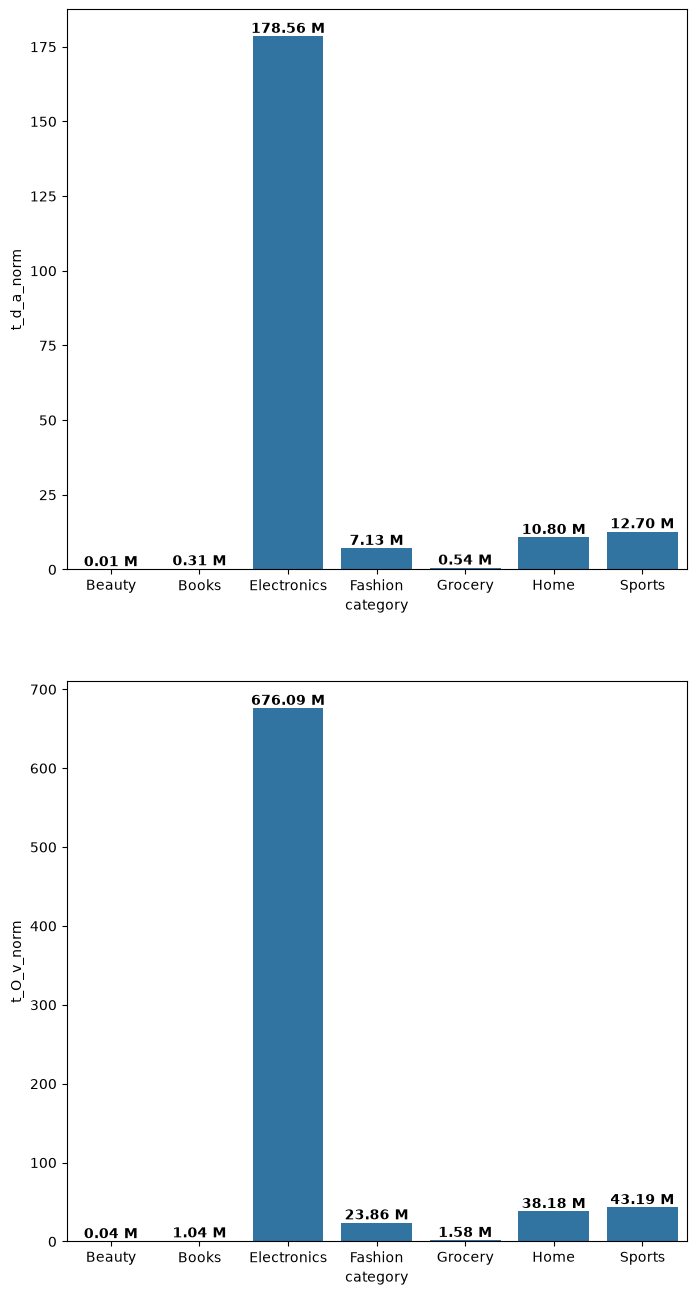

In [25]:
plt.figure(figsize=(8,16))

plt.subplot(2,1,1)

ax = sns.barplot(data = vip_orders, x = 'category', y = 't_d_a_norm')

for container in ax.containers:
    ax.bar_label(container, weight = 'bold', fmt= '%.2f M')

plt.subplot(2,1,2)

ax1 = sns.barplot(data = vip_orders, x = 'category', y = 't_O_v_norm')

for container in ax1.containers:
    ax1.bar_label(container, weight = 'bold', fmt= '%.2f M')


plt.show()

In [26]:
top_5_pec_orders['delivery_lead_time'] = top_5_pec_orders['delivery_date'] - top_5_pec_orders['order_date']

In [27]:
top_5_pec_orders.groupby('delivery_lead_time').agg(
    avg_rating = ('rating','mean'),
    total_orders = ('order_id','count')
)

,avg_rating,total_orders
delivery_lead_time,,
2 days,4.385331,3021
3 days,4.409874,2966
4 days,4.407575,2904
5 days,4.376464,2838
6 days,4.412063,2969
7 days,4.404734,2908


* **Good news** our VIPs are highly resilient and satisfied. The data proves they value our products over extreme delivery speed. We do not need to base the new loyalty program's core value proposition on lightning-fast shipping to keep our top spenders happy.
* We have identified a massive cost-saving opportunity. Since delivery times up to a full week do not negatively impact VIP satisfaction, we can avoid subsidizing expensive expedited shipping for the loyalty program, which will help protect our overall profit margins.